# 02. Chạy tay mức A
Đồ thị 12 quận, đơn vị km. Bảng từng bước do chương trình in ra để đối chiếu với kết quả chạy tay.

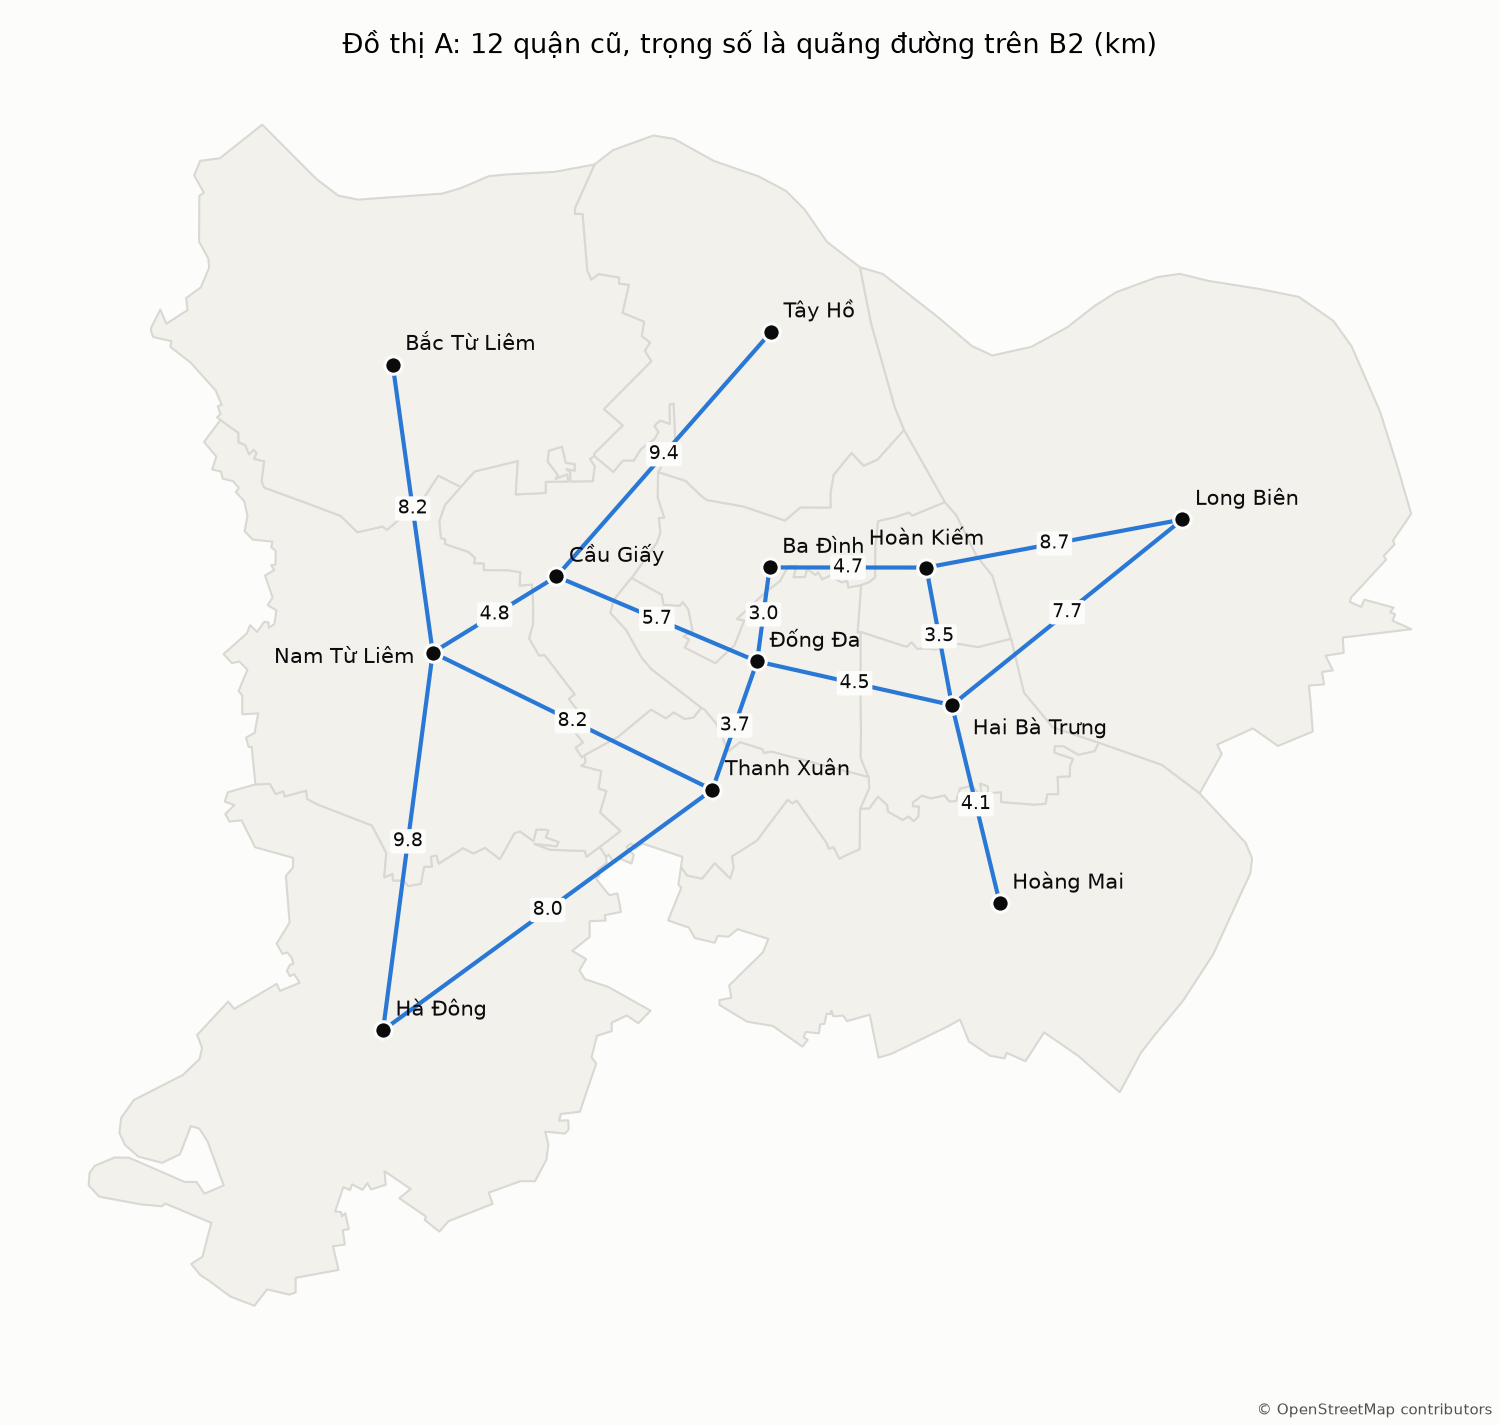

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", None, "display.width", 200, "display.max_colwidth", 120)
from src.config import PATHS, load_config
from src.data.loaders import load_heuristic_matrix, load_search_graph
from src.search import run
from src.search.heuristics import from_matrix
from IPython.display import Image, display

sg = load_search_graph("A")
matrix = load_heuristic_matrix()
heuristic = lambda graph, target: from_matrix(matrix, target)
display(Image(PATHS.FIGURES / "fig_levelA_graph.png", width=620))

## Danh sách cạnh và bảng h (km)

In [2]:
edges = pd.read_csv(PATHS.TABLES / "A_edges.csv")
accepted = edges[edges["accepted"]].assign(weight_km=lambda d: d["weight_m"] / 1000)
display(accepted[["u", "v", "weight_km", "inside_ratio", "reason"]])
display(pd.read_csv(PATHS.TABLES / "A_heuristic_matrix.csv", index_col=0) / 1000)
display(edges[~edges["accepted"]][["u", "v", "inside_ratio", "reason"]])

,u,v,weight_km,inside_ratio,reason
0,BD,HK,4.7,0.9961,rule
4,BD,DD,3.0,1.0000,rule
5,HK,LB,8.7,1.0000,rule
7,HK,HBT,3.5,1.0000,rule
9,TH,CG,9.4,0.9568,rule
11,LB,HBT,7.7,1.0000,rule
13,CG,DD,5.7,0.9998,rule
15,CG,NTL,4.8,1.0000,rule
17,DD,HBT,4.5,1.0000,rule
18,DD,TX,3.7,1.0000,rule


,BD,HK,TH,LB,CG,DD,HBT,HM,TX,HD,NTL,BTL
id,,,,,,,,,,,,
BD,0.0,2.8,4.2,7.5,3.8,1.7,4.1,7.4,4.1,10.9,6.3,7.7
HK,2.8,0.0,5.1,4.7,6.7,3.5,2.5,6.2,5.6,12.9,9.1,10.3
TH,4.2,5.1,0.0,8.2,5.9,6.0,7.5,11.2,8.4,14.5,8.4,6.9
LB,7.5,4.7,8.2,0.0,11.4,8.1,5.3,7.7,9.8,17.2,13.8,14.6
CG,3.8,6.7,5.9,11.4,0.0,3.9,7.5,10.0,4.8,8.8,2.6,4.8
DD,1.7,3.5,6.0,8.1,3.9,0.0,3.6,6.2,2.4,9.5,5.9,8.5
HBT,4.1,2.5,7.5,5.3,7.5,3.6,0.0,3.7,4.6,11.9,9.5,11.9
HM,7.4,6.2,11.2,7.7,10.0,6.2,3.7,0.0,5.6,11.4,11.2,14.7
TX,4.1,5.6,8.4,9.8,4.8,2.4,4.6,5.6,0.0,7.4,5.6,9.6


,u,v,inside_ratio,reason
1,BD,TH,0.7675,inside_ratio < 0.9
2,BD,LB,0.6705,inside_ratio < 0.9
3,BD,CG,0.8976,inside_ratio < 0.9
6,HK,DD,0.8323,inside_ratio < 0.9
8,TH,LB,0.6707,inside_ratio < 0.9
10,TH,BTL,0.6003,inside_ratio < 0.9
12,LB,HM,0.7964,inside_ratio < 0.9
14,CG,TX,0.6374,inside_ratio < 0.9
16,CG,BTL,0.8249,inside_ratio < 0.9
20,HBT,TX,0.4965,inside_ratio < 0.9


## Chọn cặp để chạy tay
Lấy ứng viên đầu tiên mà đường của GBFS **khác** đường của A\*. `runs_A.csv` không có cột đường đi nên so sánh trực tiếp.

In [3]:
candidates = load_config("experiment")["level_A"]["hand_trace_candidates"]
rows = []
for s, t in candidates:
    gbfs = run("GBFS", sg, s, t, heuristic)
    astar = run("ASTAR", sg, s, t, heuristic)
    rows.append({"cặp": f"{s} → {t}", "GBFS": gbfs.path, "A*": astar.path, "gbfs_km": gbfs.cost_m / 1000, "astar_km": astar.cost_m / 1000, "khác đường": gbfs.path != astar.path})
display(pd.DataFrame(rows))
chosen = next((pair for pair, row in zip(candidates, rows) if row["khác đường"]), None)
if chosen is None:
    runs_a = pd.read_csv(PATHS.TABLES / "runs_A.csv")
    worst = runs_a[runs_a["algorithm"] == "GBFS"].sort_values(["gap_pct", "case_id"], ascending=[False, True]).iloc[0]
    chosen = [worst["source"], worst["target"]]
    print("Cả hai ứng viên đều cho cùng đường; dùng cặp có gap(GBFS) lớn nhất:", chosen)
S, T = chosen
print("Cặp chạy tay:", S, "→", T)

,cặp,GBFS,A*,gbfs_km,astar_km,khác đường
0,LB → HD,"[LB, HBT, DD, TX, HD]","[LB, HBT, DD, TX, HD]",23.9,23.9,False
1,HM → TH,"[HM, HBT, DD, CG, TH]","[HM, HBT, DD, CG, TH]",23.7,23.7,False


Cả hai ứng viên đều cho cùng đường; dùng cặp có gap(GBFS) lớn nhất: ['TX', 'CG']
Cặp chạy tay: TX → CG


## Bảng từng bước

In [4]:
def km(value):
    return "" if value is None else f"{value / 1000:.1f}"

def step_table(algorithm):
    result = run(algorithm, sg, S, T, heuristic, trace_level="steps")
    rows = []
    for step in result.steps:
        frontier = ", ".join(f"{n}" if f is None else f"{n}: {km(f)}" for n, f in step["frontier"])
        rows.append({"Bước": step["step"], "Rút ra": step["popped"], "g": km(step["g"]), "h": km(step["h"]), "f": km(step["f"]),
                     "Frontier sau bước (nút: f)": frontier, "Closed": ", ".join(step["closed"])})
    print(f"{algorithm}: đường {' → '.join(result.path)}, {result.cost_m / 1000:.1f} km, {result.hops} cạnh, mở rộng {result.expanded} nút")
    display(pd.DataFrame(rows).style.hide(axis="index"))
    return result

results = {algorithm: step_table(algorithm) for algorithm in ["BFS", "GBFS", "ASTAR"]}

BFS: đường TX → DD → CG, 9.4 km, 2 cạnh, mở rộng 6 nút


Bước,Rút ra,g,h,f,Frontier sau bước (nút: f),Closed
1,TX,0.0,,,"DD, HD, NTL",TX
2,DD,3.7,,,"HD, NTL, BD, CG, HBT","DD, TX"
3,HD,8.0,,,"NTL, BD, CG, HBT","DD, HD, TX"
4,NTL,8.2,,,"BD, CG, HBT, BTL","DD, HD, NTL, TX"
5,BD,6.7,,,"CG, HBT, BTL, HK","BD, DD, HD, NTL, TX"
6,CG,9.4,,,"HBT, BTL, HK","BD, CG, DD, HD, NTL, TX"


GBFS: đường TX → NTL → CG, 13.0 km, 2 cạnh, mở rộng 3 nút


Bước,Rút ra,g,h,f,Frontier sau bước (nút: f),Closed
1,TX,0.0,4.8,4.8,"NTL: 2.6, DD: 3.9, HD: 8.8",TX
2,NTL,8.2,2.6,2.6,"CG: 0.0, DD: 3.9, BTL: 4.8, HD: 8.8","NTL, TX"
3,CG,13.0,0.0,0.0,"DD: 3.9, BTL: 4.8, HD: 8.8","CG, NTL, TX"


ASTAR: đường TX → DD → CG, 9.4 km, 2 cạnh, mở rộng 3 nút


Bước,Rút ra,g,h,f,Frontier sau bước (nút: f),Closed
1,TX,0.0,4.8,4.8,"DD: 7.6, NTL: 10.8, HD: 16.8",TX
2,DD,3.7,3.9,7.6,"CG: 9.4, BD: 10.5, NTL: 10.8, HBT: 15.7, HD: 16.8","DD, TX"
3,CG,9.4,0.0,9.4,"BD: 10.5, NTL: 10.8, HBT: 15.7, HD: 16.8","CG, DD, TX"


## So sánh trên cặp này

In [5]:
pd.DataFrame([{"thuật toán": a, "đường đi": " → ".join(r.path), "km": r.cost_m / 1000, "cạnh": r.hops, "nút mở rộng": r.expanded} for a, r in results.items()])

,thuật toán,đường đi,km,cạnh,nút mở rộng
0,BFS,TX → DD → CG,9.4,2,6
1,GBFS,TX → NTL → CG,13.0,2,3
2,ASTAR,TX → DD → CG,9.4,2,3
